# Seismic Refraction (RF) — Line L1 (soccer field)

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from utils import seg2_io, refraction, plotting, interpretation

# --- Data ---
DATA_FOLDER = "L1/RF"
# The SEG-2 header of this shot says 42.5 m but the filename says 47.5 m;
# 47.5 m fits the traveltime data better (confirm against field notes).
SOURCE_X_OVERRIDES = {"2026-10-08_RF_47.5m.dat": 47.5}

# --- First-break picking (offset-guided) ---
# Velocity range bounding the move-out between neighboring receivers.
# Soccer field: soft turf/topsoil direct wave ~200-300 m/s,
# compacted/saturated refractor well below 1500 m/s.
PICK_V_MIN = 150.0          # m/s
PICK_V_MAX = 1500.0         # m/s
PICK_NOISE_WINDOW = 0.010   # s, pre-arrival window used to estimate noise
PICK_THRESHOLD = 3.0        # trigger at threshold x noise RMS
# 3.0 chosen from a parameter sweep (2.5-8): it picks the weak far-offset
# onsets that 5.0 missed (late picks on the next lobe, 8 of 60 rejected by
# QC) while 2.5 started triggering on pre-arrival noise (shot +47.5 m).
# Manual corrections: {(shot_index, receiver_index): time_s or np.nan to discard}
PICK_OVERRIDES = {}


# --- 2D traveltime tomography (pyGIMLi) ---
PICK_ERROR = 0.0035         # s, pick uncertainty; ~ the residual RMS floor (3.3 ms)
                            # reached with the threshold-3 picks (5 ms underfit them)
# Mesh style: PARA_DX is RELATIVE to the sensor spacing, not meters
# (1 = nodes only at sensors, 0.5 = one extra node between sensors,
#  0.33 = two, 0.1 = nine -> very fine, slow, no extra real resolution).
PARA_DX = 0.33
PARA_DEPTH = 12.0           # m, model depth (~ spread length / 5)
MESH_QUALITY = 33.5       # min triangle angle (deg); keep <= 34 or the mesher hangs
MAX_CELL_SIZE = 1.0     # m^2, cap on triangle area (None = automatic)
SHOW_MESH = True            # overlay mesh edges on the final tomogram
LAM = 100.0                  # regularization strength (with CORR_LENGTHS below)
# Geostatistical regularization: correlation lengths [horizontal, vertical] in m.
# Horizontal >> vertical forces a laterally continuous, horizontally layered
# model (flat field site). Sweep result: (80, 1) with lam 50 gave the flattest
# layers (lateral/vertical variation 0.12 vs 0.47 with Z_WEIGHT alone) at chi2 ~ 1.3.
# Set CORR_LENGTHS = None to fall back to Z_WEIGHT-only regularization.
CORR_LENGTHS = [80.0, 1.0]
Z_WEIGHT = 1.0              # only used when CORR_LENGTHS is None (< 1 favors layers)
PARA_BOUNDARY = 0.5         # lateral mesh margin beyond the sensors, in sensor spacings
V_TOP, V_BOTTOM = 250.0, 1500.0  # m/s, starting-model gradient for soft soil
MAX_RESIDUAL = 0.010        # s (~3 x PICK_ERROR), picks worse than this after QC inversion are dropped
# --- Joint interpretation (uses the Vs profile exported by L1_MASW_analysis) ---
MASW_VS_CSV = "L1/MASW_vs_profile.csv"
X_CENTER = 27.5             # m, where the 1D Vp(z) profile is extracted
Z_MIN_INTERP, Z_MAX_INTERP = 0.5, 10.0  # m, interpreted depth range
RHO = 1800.0                # kg/m3, assumed soil density
INTERPRETATION_FIG = "L1/L1_joint_interpretation.png"


## 1. Load shot gathers

In [16]:
gathers = seg2_io.read_line(DATA_FOLDER, source_x_overrides=SOURCE_X_OVERRIDES)

Read 5 shot gathers from L1/RF:
  2026-10-08_RF_-5m.dat: source at -5.0 m, 12 receivers (0.0-55.0 m), 4096 samples at 8000 Hz
  2026-10-08_RF_12.5m.dat: source at +12.5 m, 12 receivers (0.0-55.0 m), 4096 samples at 8000 Hz
  2026-10-08_RF_27.5m.dat: source at +27.5 m, 12 receivers (0.0-55.0 m), 4096 samples at 8000 Hz
  2026-10-08_RF_47.5m.dat: source at +47.5 m, 12 receivers (0.0-55.0 m), 4096 samples at 8000 Hz
  2026-10-08_RF_60m.dat: source at +60.0 m, 12 receivers (0.0-55.0 m), 4096 samples at 8000 Hz


## 2. First-break picking

In [17]:
picks = refraction.pick_line(
    gathers,
    overrides=PICK_OVERRIDES,
    v_min=PICK_V_MIN,
    v_max=PICK_V_MAX,
    noise_window=PICK_NOISE_WINDOW,
    threshold=PICK_THRESHOLD,
)
refraction.picks_table(gathers, picks)

,source -5.0 m,source +12.5 m,source +27.5 m,source +47.5 m,source +60.0 m
0.0 m,6.62,16.62,24.75,59.50,52.62
5.0 m,13.12,8.38,20.12,52.62,49.38
10.0 m,17.12,9.12,19.25,47.62,46.38
15.0 m,19.38,9.12,15.12,36.38,43.38
20.0 m,22.88,8.38,12.12,33.38,32.75
25.0 m,25.75,16.62,9.88,28.38,28.12
30.0 m,29.00,18.62,11.00,23.62,25.00
35.0 m,31.88,19.88,12.12,20.38,22.88
40.0 m,38.88,33.50,15.12,18.50,21.12
45.0 m,46.38,36.00,19.25,12.12,15.00


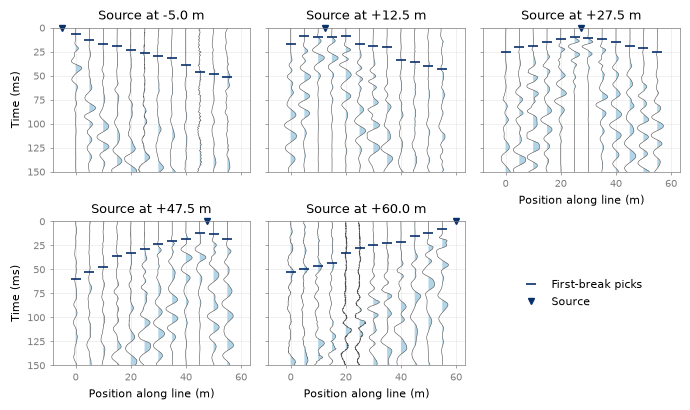

In [18]:
plotting.plot_all_gathers(
    gathers, t_max=0.15, picks_per_shot=picks,
    ncols=3, width=7.0, panel_aspect=0.9, fontsize=8,
    scale=0.45,                 # wiggle amplitude (fraction of trace spacing)
    fill_color="#9ecae1", fill_alpha=0.8,
    line_color="#4d4d4d", line_width=0.4,
    pick_color="#08306b", pick_size=7, source_size=5,
    axis_color="#7f7f7f",       # spines, tick marks, tick values
    label_color="k",            # axis labels and titles
    grid_color="#e5e5e5",       # None removes the grid
    legend_loc="center",        # position inside the spare slot
)
plt.show()

## 3. Traveltime curves

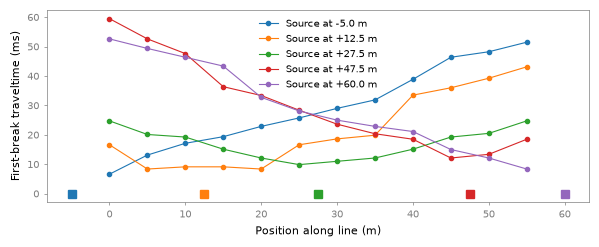

In [19]:
plotting.plot_traveltime_curves(
    gathers, picks,
    width=7.0, height=2.5, fontsize=8,
    line_width=0.8, marker="o", marker_size=3,
    source_marker="s", source_size=6,
    axis_color="#7f7f7f", label_color="k",
    grid_color="None",      # None removes the grid
    legend_loc="best",         # e.g. "upper center" or "center right"
    colors=None,               # list of colors to replace tab10
)
plt.show()

## 4. Apparent velocity analysis

In [20]:
# With 5 m geophone spacing on soft ground the direct wave is only seen at
# the very nearest offsets, so the classic two-layer intercept method is not
# applicable; apparent velocities per shot/direction are reported instead.
refraction.apparent_velocities(gathers, picks)


,source_x_m,side,n_picks,v_apparent_m_s,intercept_ms
0,-5.0,right,12,1251.9,3.27
1,12.5,left,3,1333.3,5.75
2,12.5,right,9,1062.9,3.78
3,27.5,left,6,1707.3,8.09
4,27.5,right,6,1785.7,8.73
5,47.5,left,10,976.6,7.65
6,60.0,left,12,1206.1,2.81


## 5. 2D traveltime tomography (pyGIMLi)

### 5.1 QC inversion & outlier rejection

### 5.0 Inversion mesh preview

22/10/26 - 19:03:47 - pyGIMLi - INFO - Found 1 regions.


Traveltime data: 17 sensors, 60 picks
Mesh: 1510 cells, 826 nodes (paraDX=0.33, depth=12.0 m, quality=33.5)


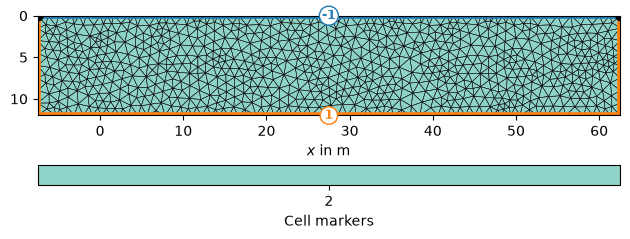

In [21]:
import pygimli as pg
pg.show(refraction.create_mesh(
    refraction.build_traveltime_data(gathers, picks, pick_error=PICK_ERROR),
    para_dx=PARA_DX, para_depth=PARA_DEPTH,
    quality=MESH_QUALITY, max_cell_size=MAX_CELL_SIZE,
    para_boundary=PARA_BOUNDARY,
), markers=True, showMesh=True)
plt.show()

In [22]:
data_tt = refraction.build_traveltime_data(gathers, picks, pick_error=PICK_ERROR)
mesh = refraction.create_mesh(
    data_tt, para_dx=PARA_DX, para_depth=PARA_DEPTH,
    quality=MESH_QUALITY, max_cell_size=MAX_CELL_SIZE,
    para_boundary=PARA_BOUNDARY,
)
manager_qc = refraction.invert_tomography(
    data_tt, mesh=mesh, lam=LAM, z_weight=Z_WEIGHT, v_top=V_TOP, v_bottom=V_BOTTOM,
    correlation_lengths=CORR_LENGTHS,
)
picks_clean = refraction.drop_outlier_picks(
    gathers, picks, manager_qc, data_tt, max_residual=MAX_RESIDUAL,
)

22/10/26 - 19:03:47 - pyGIMLi - INFO - Found 1 regions.
22/10/26 - 19:03:47 - pyGIMLi - INFO - Found 1 regions.
22/10/26 - 19:03:47 - pyGIMLi - INFO - Creating forward mesh from region infos.
22/10/26 - 19:03:47 - pyGIMLi - INFO - Creating refined mesh (secnodes: 2) to solve forward task.


Traveltime data: 17 sensors, 60 picks
Mesh: 1510 cells, 826 nodes (paraDX=0.33, depth=12.0 m, quality=33.5)


22/10/26 - 19:03:47 - pyGIMLi - INFO - Create gradient starting model. 250.0: 1500.0
22/10/26 - 19:03:47 - pyGIMLi - INFO - Creating GeostatisticConstraintsMatrix for region 2 with: I=[80.0, 1.0], dip=0, strike=0
22/10/26 - 19:03:47 - pyGIMLi - INFO - Cache /home/orincon/miniconda3/envs/seismic-l1/lib/python3.12/site-packages/pygimli/math/matrix.py:createCm05 restored (1.6s x 12): /home/orincon/.cache/pygimli/5318243034714164973
22/10/26 - 19:03:47 - Core - ERROR - no cWeights defined. You should create constraints matrix first.


Inversion finished: chi2 = 1.82, Vp = 369-1518 m/s (mean 1211 m/s)
Dropped pick: shot +47.5 m, receiver 0.0 m (residual +16.7 ms)
Dropped pick: shot +47.5 m, receiver 5.0 m (residual +13.2 ms)
Dropped pick: shot +47.5 m, receiver 10.0 m (residual +11.6 ms)


### 5.2 Final inversion

In [23]:
data_clean = refraction.build_traveltime_data(gathers, picks_clean, pick_error=PICK_ERROR)
manager = refraction.invert_tomography(
    data_clean, para_dx=PARA_DX, para_depth=PARA_DEPTH,
    quality=MESH_QUALITY, max_cell_size=MAX_CELL_SIZE,
    para_boundary=PARA_BOUNDARY,
    lam=LAM, z_weight=Z_WEIGHT, v_top=V_TOP, v_bottom=V_BOTTOM,
    correlation_lengths=CORR_LENGTHS,
)

22/10/26 - 19:03:50 - pyGIMLi - INFO - Found 1 regions.


22/10/26 - 19:03:50 - pyGIMLi - INFO - Found 1 regions.
22/10/26 - 19:03:50 - pyGIMLi - INFO - Creating forward mesh from region infos.
22/10/26 - 19:03:50 - pyGIMLi - INFO - Creating refined mesh (secnodes: 2) to solve forward task.
22/10/26 - 19:03:50 - pyGIMLi - INFO - Create gradient starting model. 250.0: 1500.0


Traveltime data: 17 sensors, 57 picks
Mesh: 1510 cells, 826 nodes (paraDX=0.33, depth=12.0 m, quality=33.5)


22/10/26 - 19:03:50 - pyGIMLi - INFO - Creating GeostatisticConstraintsMatrix for region 2 with: I=[80.0, 1.0], dip=0, strike=0
22/10/26 - 19:03:50 - pyGIMLi - INFO - Cache /home/orincon/miniconda3/envs/seismic-l1/lib/python3.12/site-packages/pygimli/math/matrix.py:createCm05 restored (1.6s x 13): /home/orincon/.cache/pygimli/5318243034714164973
22/10/26 - 19:03:50 - Core - ERROR - no cWeights defined. You should create constraints matrix first.




Inversion finished: chi2 = 1.00, Vp = 373-1492 m/s (mean 1266 m/s)


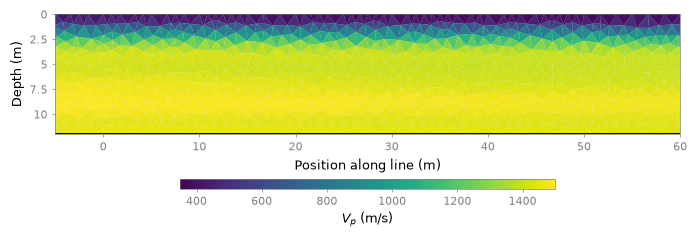

In [24]:
plotting.plot_tomogram(
    manager, width=7.0, height=2.2, fontsize=8,
    label_size=9,
    tick_size=8,
    cmap="viridis", v_min=None, v_max=None,   # color limits, default model range rounded to 50 m/s
    show_mesh=None,
    v_exag=0.1,
    cbar_label="$V_{p}$ (m/s)",
    cbar_thickness=0.1,
    mesh_color="k",     # any matplotlib color
    mesh_alpha=0.3,     # 0 invisible, 1 opaque
    mesh_width=0.2,     # line width in pt                   # True draws the cell edges as in your first reference
    rays=None, ray_color="w", ray_alpha=0.5, ray_width=0.5,
    axis_color="#7f7f7f", label_color="k",
    xlim=(-5, 60),             # crop to the sensor range
    title=None,
)
plt.show()

## 6. Joint interpretation: material classification ($V_p$ + $V_s$)

In [25]:
vp_profile = interpretation.vp_profile_from_tomogram(
    manager, x_center=X_CENTER, z_min=Z_MIN_INTERP, z_max=Z_MAX_INTERP,
)
vs_profile = pd.read_csv(MASW_VS_CSV)
properties = interpretation.elastic_properties(vp_profile, vs_profile, rho=RHO)
layers = interpretation.classify_materials(properties)
layers.drop(columns="color")

,top_m,bottom_m,vp_mean_m_s,vs_mean_m_s,poisson_mean,material
0,1.47,4.03,1122.0,331.0,0.45,Stiff soil: compacted sandy/clayey fill
1,4.03,10.00,1442.0,478.0,0.44,Very dense soil / gravelly subbase


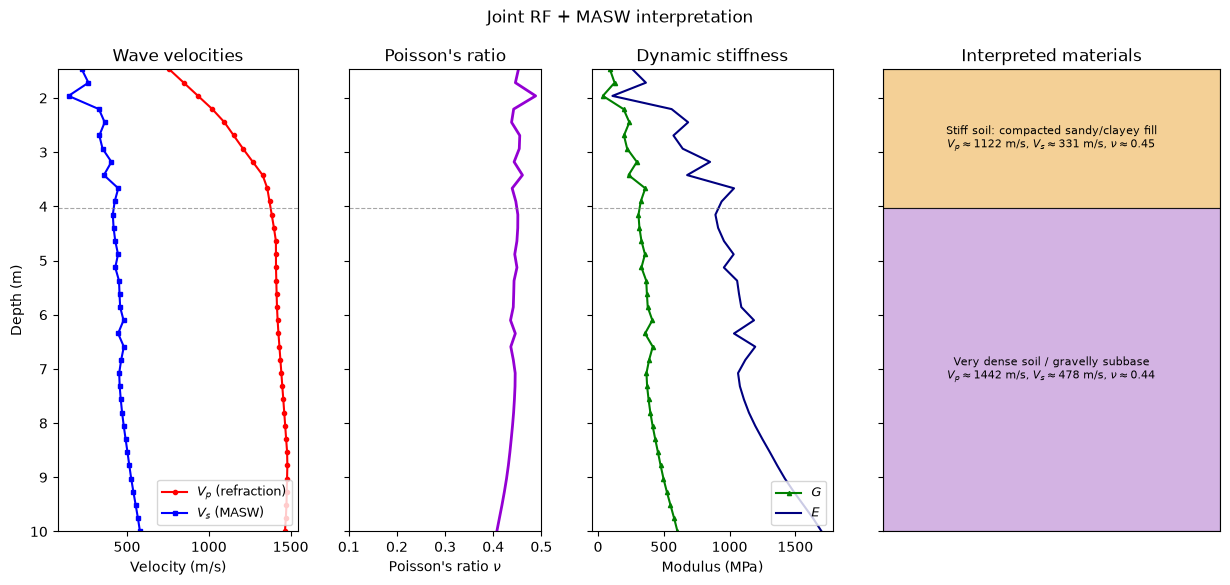

Figure saved to L1/L1_joint_interpretation.png


In [26]:
interpretation.plot_interpretation(properties, layers)
plt.savefig(INTERPRETATION_FIG, dpi=300, bbox_inches="tight")
plt.show()
print(f"Figure saved to {INTERPRETATION_FIG}")